In [1]:
%pip install hitran-api numpy matplotlib pandas scipy

Note: you may need to restart the kernel to use updated packages.


HAPI version: 1.3.0.0
To get the most up-to-date version please check http://hitran.org/hapi
ATTENTION: Python versions of partition sums from TIPS-2021 are now available in HAPI code

           MIT license: Copyright 2021 HITRAN team, see more at http://hitran.org. 

           If you use HAPI in your research or software development,
           please cite it using the following reference:
           R.V. Kochanov, I.E. Gordon, L.S. Rothman, P. Wcislo, C. Hill, J.S. Wilzewski,
           HITRAN Application Programming Interface (HAPI): A comprehensive approach
           to working with spectroscopic data, J. Quant. Spectrosc. Radiat. Transfer 177, 15-30 (2016)
           DOI: 10.1016/j.jqsrt.2016.03.005

           ATTENTION: This is the core version of the HITRAN Application Programming Interface.
                      For more efficient implementation of the absorption coefficient routine, 
                      as well as for new profiles, parameters and other functional,
      

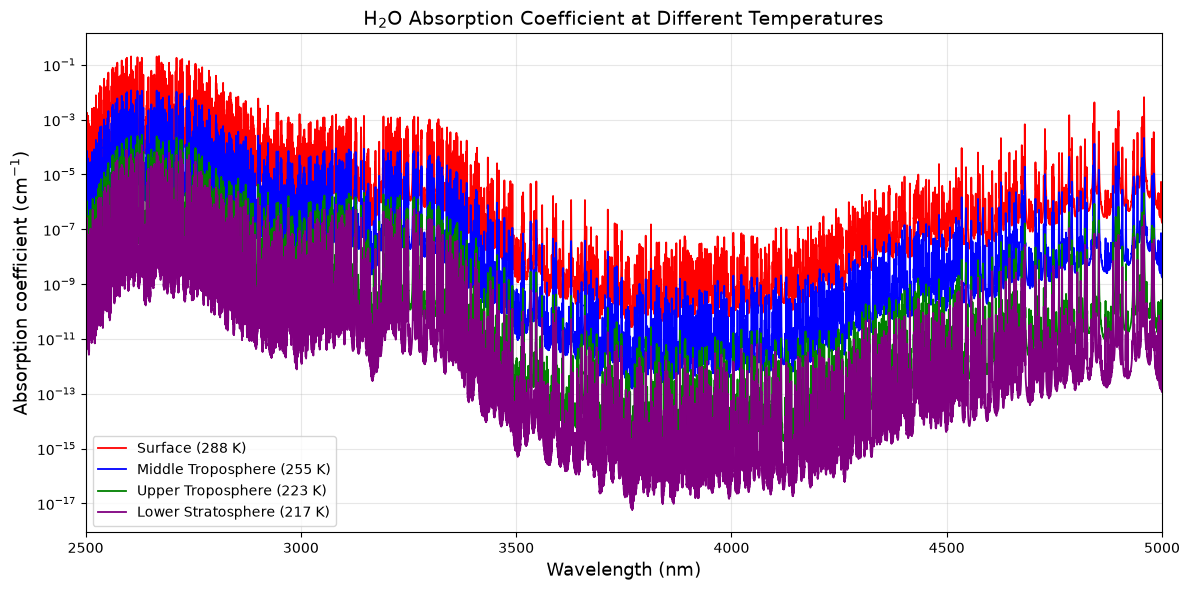

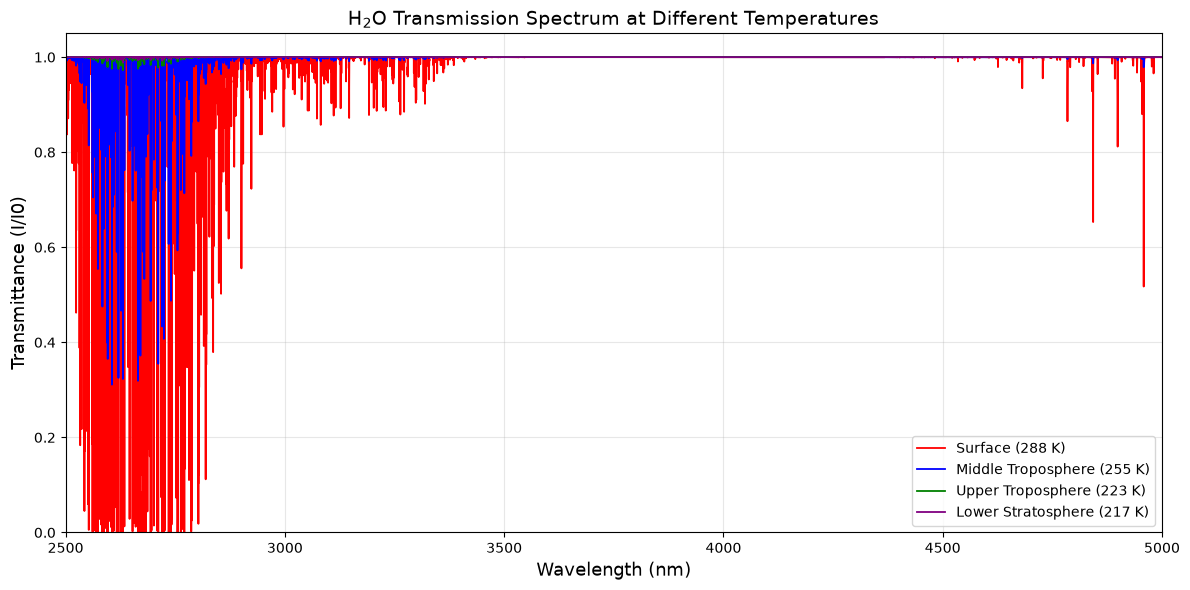

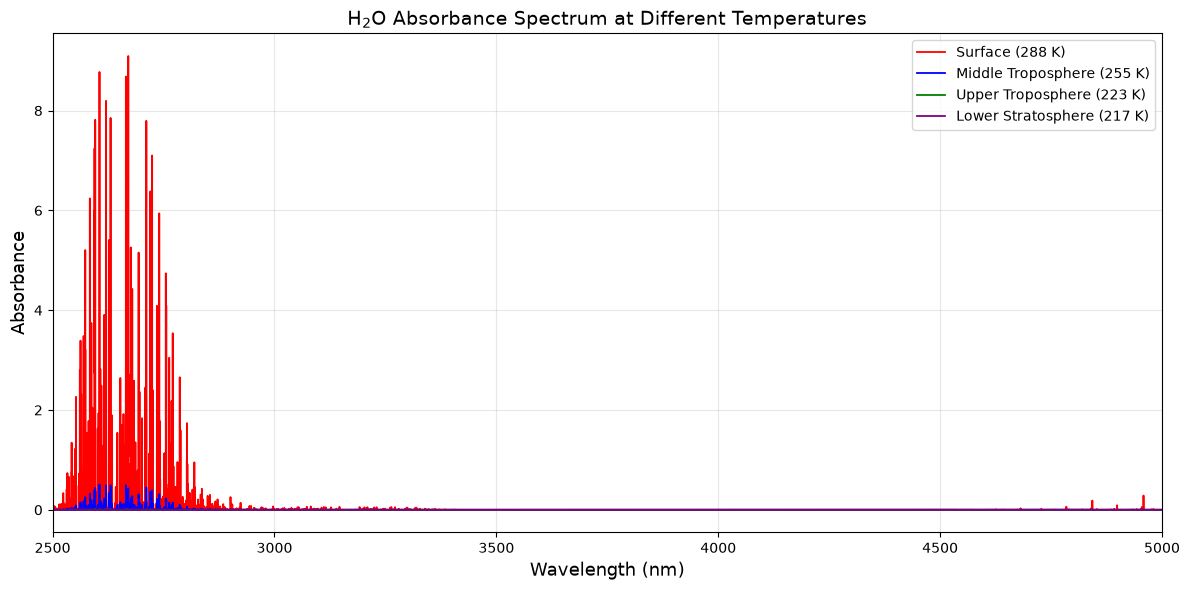


       SIMULATION SUCCESSFUL
Generated files:
1. H2O_Absorption_Coefficient.png
2. H2O_Transmission.png
3. H2O_Absorbance.png
4. H2O_Atmospheric_HITRAN_Data.csv

Atmospheric conditions:
Surface (288 K) | Temperature: 288 K | Pressure: 1013 hPa | H2O: 1.0 %
Middle Troposphere (255 K) | Temperature: 255 K | Pressure: 540 hPa | H2O: 0.05 %
Upper Troposphere (223 K) | Temperature: 223 K | Pressure: 265 hPa | H2O: 0.001 %
Lower Stratosphere (217 K) | Temperature: 217 K | Pressure: 55 hPa | H2O: 0.0005 %


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hapi
from scipy.constants import Boltzmann

# =====================================================
# 1. CREATE HITRAN DATABASE
# =====================================================

DATABASE = "H2O_HITRAN_ATMOSPHERE"

os.makedirs(DATABASE, exist_ok=True)
hapi.db_begin(DATABASE)

# =====================================================
# 2. DOWNLOAD H2O DATA FROM HITRAN
# =====================================================

nu_min = 2000.0
nu_max = 4000.0

TABLE = "H2O"

print("Checking HITRAN H2O data...")

if TABLE not in hapi.tableList():

    print("Downloading H2O data...")

    hapi.fetch(
        TABLE,
        1,
        1,
        nu_min,
        nu_max
    )

else:
    print("H2O HITRAN data already exists.")

print("HITRAN data ready!")

# =====================================================
# 3. ATMOSPHERIC TEMPERATURE CONDITIONS
# =====================================================

conditions = {

    "Surface (288 K)": {
        "T": 288,
        "P": 1013,
        "VMR": 0.010
    },

    "Middle Troposphere (255 K)": {
        "T": 255,
        "P": 540,
        "VMR": 0.0005
    },

    "Upper Troposphere (223 K)": {
        "T": 223,
        "P": 265,
        "VMR": 0.00001
    },

    "Lower Stratosphere (217 K)": {
        "T": 217,
        "P": 55,
        "VMR": 0.000005
    }
}

# =====================================================
# 4. PHYSICAL PARAMETERS
# =====================================================

path_length_cm = 100.0

omega_step = 0.02
omega_wing = 25.0

spectra = {}

# =====================================================
# 5. HITRAN ABSORPTION CALCULATION
# =====================================================

for layer, condition in conditions.items():

    T = condition["T"]
    P_hPa = condition["P"]
    VMR = condition["VMR"]

    print(f"\nCalculating {layer}...")

    P_atm = P_hPa / 1013.25

    # Air and self broadening
    diluent = {
        "air": 1.0 - VMR,
        "self": VMR
    }

    nu, alpha_pure = hapi.absorptionCoefficient_Voigt(

        SourceTables=TABLE,

        Components=[(1, 1, 1.0)],

        Environment={
            "T": float(T),
            "p": float(P_atm)
        },

        Diluent=diluent,

        OmegaRange=(nu_min, nu_max),

        OmegaStep=omega_step,

        OmegaWing=omega_wing,

        HITRAN_units=False
    )

    nu = np.asarray(nu, dtype=float)
    alpha_pure = np.asarray(alpha_pure, dtype=float)

    if len(nu) == 0:
        raise RuntimeError(f"No data returned for {layer}")

    # =================================================
    # 6. WATER VAPOUR NUMBER DENSITY
    # =================================================

    P_Pa = P_hPa * 100

    n_total = P_Pa / (Boltzmann * T) / 1e6

    n_water = n_total * VMR

    # HAPI coefficient scaled to water vapour abundance
    alpha = alpha_pure * VMR

    # =================================================
    # 7. BEER-LAMBERT LAW
    # =================================================

    optical_depth = alpha * path_length_cm

    transmission = np.exp(
        -np.clip(optical_depth, 0, 700)
    )

    absorbance = optical_depth / np.log(10)

    absorption_fraction = 1 - transmission

    # =================================================
    # 8. CONVERT WAVENUMBER TO WAVELENGTH
    # =================================================

    wavelength_nm = 1e7 / nu

    order = np.argsort(wavelength_nm)

    wavelength_nm = wavelength_nm[order]
    alpha = alpha[order]
    transmission = transmission[order]
    absorbance = absorbance[order]
    absorption_fraction = absorption_fraction[order]

    spectra[layer] = {

        "wavelength": wavelength_nm,
        "alpha": alpha,
        "transmission": transmission,
        "absorbance": absorbance,
        "absorption_fraction": absorption_fraction
    }

    print(
        "Maximum absorption coefficient:",
        np.max(alpha)
    )

print("\nAll temperature calculations completed!")

# =====================================================
# 9. GRAPH 1: ABSORPTION COEFFICIENT
# =====================================================

plt.figure(figsize=(12, 6))

colors = ["red", "blue", "green", "purple"]

for (layer, color) in zip(conditions, colors):

    wavelength = spectra[layer]["wavelength"]
    alpha = spectra[layer]["alpha"]

    # Prevent zero values on logarithmic scale
    alpha_plot = np.maximum(alpha, 1e-30)

    plt.plot(
        wavelength,
        alpha_plot,
        color=color,
        label=layer,
        linewidth=1.3
    )

plt.xlabel("Wavelength (nm)", fontsize=13)

plt.ylabel(
    "Absorption coefficient (cm$^{-1}$)",
    fontsize=13
)

plt.title(
    "H$_2$O Absorption Coefficient at Different Temperatures",
    fontsize=14
)

plt.yscale("log")
plt.xlim(2500, 5000)

plt.legend()
plt.grid(alpha=0.3, which="both")
plt.tight_layout()

plt.savefig(
    "H2O_Absorption_Coefficient.png",
    dpi=300
)

plt.show()

# =====================================================
# 10. GRAPH 2: TRANSMISSION
# =====================================================

plt.figure(figsize=(12, 6))

for (layer, color) in zip(conditions, colors):

    plt.plot(
        spectra[layer]["wavelength"],
        spectra[layer]["transmission"],
        color=color,
        label=layer,
        linewidth=1.3
    )

plt.xlabel("Wavelength (nm)", fontsize=13)

plt.ylabel("Transmittance (I/I0)", fontsize=13)

plt.title(
    "H$_2$O Transmission Spectrum at Different Temperatures",
    fontsize=14
)

plt.xlim(2500, 5000)
plt.ylim(0, 1.05)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "H2O_Transmission.png",
    dpi=300
)

plt.show()

# =====================================================
# 11. GRAPH 3: ABSORBANCE
# =====================================================

plt.figure(figsize=(12, 6))

for (layer, color) in zip(conditions, colors):

    plt.plot(
        spectra[layer]["wavelength"],
        spectra[layer]["absorbance"],
        color=color,
        label=layer,
        linewidth=1.3
    )

plt.xlabel("Wavelength (nm)", fontsize=13)

plt.ylabel("Absorbance", fontsize=13)

plt.title(
    "H$_2$O Absorbance Spectrum at Different Temperatures",
    fontsize=14
)

plt.xlim(2500, 5000)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "H2O_Absorbance.png",
    dpi=300
)

plt.show()

# =====================================================
# 12. SAVE ALL RESULTS IN CSV
# =====================================================

data = {
    "Wavelength_nm":
        spectra[list(conditions.keys())[0]]["wavelength"]
}

for layer in conditions:

    label = (
        layer.replace(" ", "_")
             .replace("(", "")
             .replace(")", "")
    )

    data[f"Absorption_{label}_cm-1"] = (
        spectra[layer]["alpha"]
    )

    data[f"Transmission_{label}"] = (
        spectra[layer]["transmission"]
    )

    data[f"Absorbance_{label}"] = (
        spectra[layer]["absorbance"]
    )

df = pd.DataFrame(data)

df.to_csv(
    "H2O_Atmospheric_HITRAN_Data.csv",
    index=False
)

# =====================================================
# 13. FINAL OUTPUT
# =====================================================

print("\n====================================")
print("       SIMULATION SUCCESSFUL")
print("====================================")

print("Generated files:")

print("1. H2O_Absorption_Coefficient.png")
print("2. H2O_Transmission.png")
print("3. H2O_Absorbance.png")
print("4. H2O_Atmospheric_HITRAN_Data.csv")

print("\nAtmospheric conditions:")

for layer, condition in conditions.items():

    print(
        layer,
        "| Temperature:", condition["T"], "K",
        "| Pressure:", condition["P"], "hPa",
        "| H2O:", condition["VMR"] * 100, "%"
    )


In [3]:
for layer in conditions:

    maximum = np.max(spectra[layer]["absorbance"])

    print(layer, "Maximum absorbance =", maximum)

Surface (288 K) Maximum absorbance = 9.093666285912395
Middle Troposphere (255 K) Maximum absorbance = 0.5071071676050289
Upper Troposphere (223 K) Maximum absorbance = 0.0120673921464516
Lower Stratosphere (217 K) Maximum absorbance = 0.00513804344973174


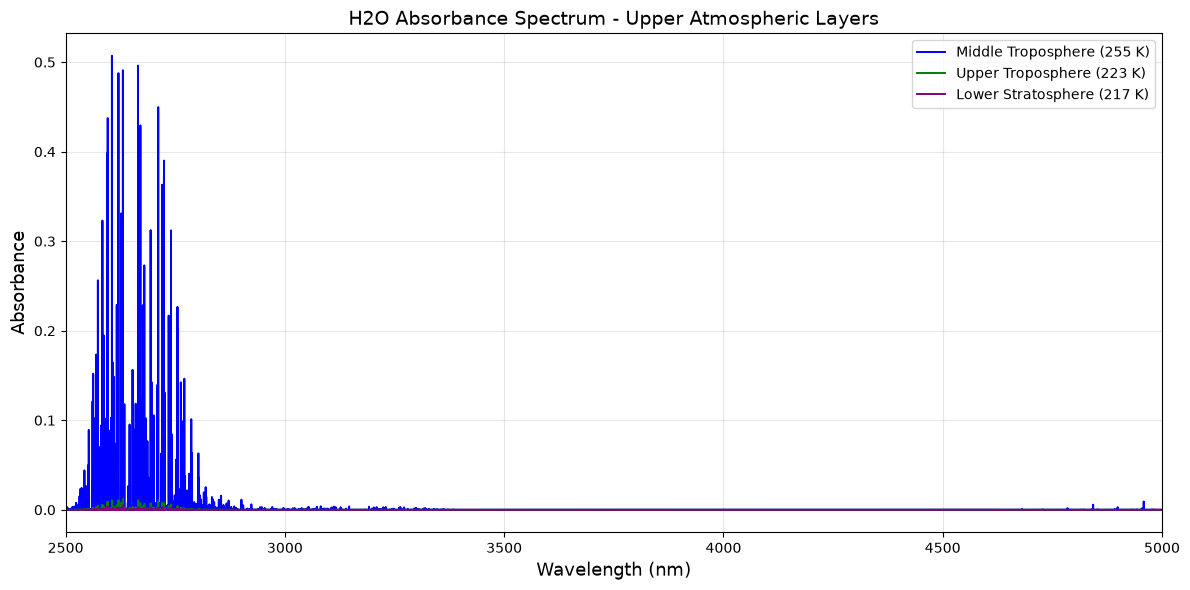

In [4]:

# =====================================================
# ABSORBANCE SPECTRUM - WEAKER ATMOSPHERIC LAYERS
# =====================================================

plt.figure(figsize=(12, 6))

colors = ["blue", "green", "purple"]

weak_layers = [
    "Middle Troposphere (255 K)",
    "Upper Troposphere (223 K)",
    "Lower Stratosphere (217 K)"
]

for layer, color in zip(weak_layers, colors):

    plt.plot(
        spectra[layer]["wavelength"],
        spectra[layer]["absorbance"],
        color=color,
        label=layer,
        linewidth=1.4
    )

plt.xlabel("Wavelength (nm)", fontsize=13)
plt.ylabel("Absorbance", fontsize=13)

plt.title(
    "H2O Absorbance Spectrum - Upper Atmospheric Layers",
    fontsize=14
)

plt.xlim(2500, 5000)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "H2O_Weak_Layers_Absorbance.png",
    dpi=300
)

plt.show()
